# 02 — سامانهٔ هشدار زودهنگام: روایت سامانهٔ نهایی

این نوتبوک چیزی را آموزش نمی‌دهد؛ فقط آنچه **یک فرمان** (`scripts/run_chain.py`) ساخته و در دیتابیس
گذاشته را می‌خواند و نشان می‌دهد: زمان هر مرحله، ویژگی‌ها، انتخاب مدل، ارزیابی در نقطهٔ عملیاتی،
جابه‌جایی داده، منبع بیرونی، هزینهٔ نشت و فهرست نهایی. هر عدد این‌جا از همان اجرا می‌آید.

- برچسب: بدترین امتیاز نظرِ سفارش ≤ ۲ (`capstone.v_order_label`).
- لحظهٔ تصمیم: `order_approved_at`. تقسیم: زمانی، روی `split.boundary`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

STAGE = Path.cwd()
if not (STAGE / "src" / "capstone").is_dir():
    STAGE = Path(os.environ.get("CAPSTONE_STAGE_DIR", STAGE)).resolve()
sys.path[:0] = [str(STAGE / "src"), str(STAGE.parent / "stage-1-kiarash-akbari" / "src")]

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from capstone.cli import default_config_path
from capstone.config import load_config
from capstone.features import connect, database_uri

CONFIG = load_config(default_config_path(STAGE))
SEED = CONFIG.model.random_seed  # the one seed the model layer uses; this notebook trains nothing itself
CURATED = CONFIG.features.curated_dir
if os.environ.get("CAPSTONE_NOTEBOOK_RUN_CHAIN") == "1":
    done = subprocess.run([sys.executable, str(STAGE / "scripts" / "run_chain.py"),
                           "--manifest", str(CURATED / "chain_manifest_notebook.json")],
                          cwd=STAGE, capture_output=True, text=True)
    print(done.returncode, done.stderr[-500:])
print("config:", CONFIG.source.name, "| boundary:", CONFIG.split.boundary, "| quota:", CONFIG.capacity.share)

config: capstone.default.toml | boundary: 2018-05-31 | quota: 0.1


## ۱. اجرای زنجیره و زمان هر مرحله (بودجه: ۴۵ دقیقه)

In [2]:
manifests = sorted(CURATED.glob("chain_manifest*.json"), key=lambda p: p.stat().st_mtime)
manifest_path = manifests[-1] if manifests else STAGE / "docs/evidence/chain-run-manifest.json"
manifest = json.loads(manifest_path.read_text())
timing = pd.DataFrame(manifest["layers"])[["name", "seconds", "status"]]
display(timing)
print(f"total {manifest['seconds_used']:.1f} s of {manifest['budget_seconds']} s budget -> {manifest['total']['status']}  ({manifest_path.name})")

,name,seconds,status
0,ingest,8.264,ok
1,load-database,56.280,ok
2,load-audit,0.179,ok
3,features,4.914,ok
4,external,3.969,ok
5,model,53.746,ok
6,capacity-list,0.057,ok


total 127.4 s of 2700 s budget -> ok  (chain-run-manifest.json)


## ۲. ویژگی‌ها: هر ستون، منبعش، چرا در لحظهٔ تأیید موجود است، و فرضیه‌اش

In [3]:
hyp = pd.read_csv(STAGE / "docs/feature_hypotheses.csv")
pd.set_option("display.max_colwidth", 90)
display(hyp)
conn = connect(database_uri(CONFIG), purpose="read the system's results")
cur = conn.cursor()
cur.execute("SELECT count(*) FROM capstone.v_feature_frame")
print("frame rows:", cur.fetchone()[0], "| features:", len(hyp) - 1, "+ 1 external")

,feature,source_columns,available_at_approval_because,hypothesis
0,prior_orders_by_customer,orders.order_approved_at; customers.customer_unique_id,window over the same customer's orders approved strictly before this one (RANGE ... 1 ...,a returning customer knows what to expect and complains less
1,days_since_prior_order,orders.order_approved_at; customers.customer_unique_id,same strict window; NULL (=first order) gets a missing indicator,a customer who comes back soon was satisfied last time
2,n_items,order_items.order_id,items are fixed when the order is placed (before approval),more items means more ways for one of them to go wrong
3,price_sum,order_items.price,price fixed at purchase,expensive orders raise expectations
4,price_spread,order_items.price,price fixed at purchase,a mixed basket (cheap + expensive) signals several shipments
5,freight_sum,order_items.freight_value,freight quoted at purchase,high freight is a remote destination or a heavy parcel
6,freight_share,order_items.price; order_items.freight_value,both fixed at purchase,paying a large share for shipping primes disappointment
7,shipping_limit_days,order_items.shipping_limit_date; orders.order_approved_at,the seller's hand-over deadline is a promise set at purchase,a late hand-over deadline leaves less slack before the promised date
8,n_sellers,order_items.seller_id,sellers fixed at purchase,several sellers means several parcels arriving at different times
9,n_products,order_items.product_id,products fixed at purchase,more distinct products means more chances of a mismatch


frame rows: 99281 | features: 29 + 1 external


## ۳. مدل: خط مبنا، دو خانواده، انتخاب روی اعتبارسنجیِ داخل پنجرهٔ آموزش

In [4]:
cur.execute("SELECT run_id, model, metrics FROM capstone.model_run ORDER BY created_at DESC LIMIT 1")
RUN_ID, MODEL, M = cur.fetchone()
display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "months"} for k, v in M["split"].items() if isinstance(v, dict)}).T)
print("run:", RUN_ID, "| chosen:", MODEL)
display(pd.DataFrame(M["selection"]))
rule = M["rule_baseline"]
display(Markdown(f"**قاعدهٔ خط مبنا** (انتخاب‌شده روی اعتبارسنجی): پیگیری سفارش‌هایی با «{rule['chosen']['rule']}» (`{rule['chosen']['column']}`)"))
display(pd.DataFrame(rule["tried"]))

,last,rows,first,labelled,negatives
fit,2018-02-28 23:48:19,59188,2016-09-15 12:16:38,58675,9042
train,2018-05-31 23:55:13,80320,2016-09-15 12:16:38,79654,12417
evaluation,2018-09-03 17:40:06,18961,2018-06-01 00:10:44,18864,2037
validation,2018-05-31 23:55:13,21132,2018-03-01 00:08:30,20979,3375


run: run-20261127T165412Z | chosen: hgb.d3


,model,family,validation_auc,validation_recall
0,logreg.c0_1,logreg,0.622747,0.187556
1,logreg.c1,logreg,0.621447,0.185185
2,hgb.d3,hgb,0.634047,0.198222
3,hgb.d6,hgb,0.636345,0.196148


**قاعدهٔ خط مبنا** (انتخاب‌شده روی اعتبارسنجی): پیگیری سفارش‌هایی با «the most items in one order» (`n_items`)

,rule,column,direction,validation_recall
0,the longest promised delivery window,promise_days,1,0.106963
1,the highest share of freight in the bill,freight_share,1,0.114667
2,the most items in one order,n_items,1,0.184296
3,the most sellers in one order,n_sellers,1,0.138370
4,the longest distance between customer and seller,customer_seller_span_sq,1,0.150222
5,the most expensive orders,price_sum,1,0.125630
6,the latest seller hand-over deadline,shipping_limit_days,1,0.116148


## ۴. ارزیابی روی ماه‌های بعد از مرز — جدول ظرفیت (ابزار تصمیم مدیر)

In [5]:
ev = M["evaluation"][MODEL]
rows = []
for name, block in [("rule: " + rule["chosen"]["column"], rule["evaluation"])] + [(k, v) for k, v in M["evaluation"].items()]:
    cap = {r["share"]: r["caught_share"] for r in block["capacity"]}
    rows.append({"model": name, "recall@5%": cap[0.05], "recall@10%": cap[0.1], "recall@20%": cap[0.2],
                 "precision@10%": block["operating_point"]["precision"], "F1@10%": block["operating_point"]["f1"],
                 "AUC": block["auc"], "AP": block["average_precision"]})
table = pd.DataFrame(rows).set_index("model")
display(table.round(4))
display(pd.DataFrame(ev["capacity"]).assign(denominator="labelled orders"))
display(pd.DataFrame(ev["capacity_all_approved"]).assign(denominator="all approved orders"))
print("model - rule, recall@10%, 95% bootstrap interval:", M["model_vs_rule_recall_delta_ci95"])

,recall@5%,recall@10%,recall@20%,precision@10%,F1@10%,AUC,AP
model,,,,,,,
rule: n_items,0.1134,0.2150,0.2931,0.2321,0.2232,0.5588,0.1378
hgb.d3,0.1487,0.2229,0.3348,0.2406,0.2314,0.6030,0.2057
hgb.d6,0.1443,0.2126,0.3348,0.2295,0.2207,0.6053,0.2025
logreg.c1,0.1394,0.2062,0.3176,0.2226,0.2141,0.5971,0.1934
logreg.c0_1,0.1404,0.2081,0.3147,0.2247,0.2161,0.5972,0.1937


,extra,share,caught,reviewed,caught_share,denominator
0,641,0.05,303,944,0.148748,labelled orders
1,1433,0.10,454,1887,0.222877,labelled orders
2,3091,0.20,682,3773,0.334806,labelled orders


,extra,share,caught,reviewed,caught_share,denominator
0,648,0.05,301,949,0.147766,all approved orders
1,1444,0.10,453,1897,0.222386,all approved orders
2,3111,0.20,682,3793,0.334806,all approved orders


model - rule, recall@10%, 95% bootstrap interval: {'low': -0.005002853473077497, 'high': 0.021134712347522778, 'mean': 0.007892276780881146, 'rounds': 200}


In [6]:
op = ev["operating_point"]
cm = pd.DataFrame([[op["tp"], op["fn"]], [op["fp"], op["tn"]]],
                  index=["actual negative review", "actual not negative"],
                  columns=["in the 10% list", "not in the list"])
display(Markdown("**Confusion matrix at the operating point (top 10%)**"))
display(cm)
print({k: round(op[k], 4) for k in ("precision", "recall", "f1")}, "AUC", round(ev["auc"], 4))

**Confusion matrix at the operating point (top 10%)**

,in the 10% list,not in the list
actual negative review,454,1583
actual not negative,1433,15394


{'precision': 0.2406, 'recall': 0.2229, 'f1': 0.2314} AUC 0.603


### پراکندگی در ماه‌های ارزیابی و معیار دوم (آخرین ماه)

,auc,month,caught,recall,labelled,reviewed,negatives
0,0.629878,2018-06,173,0.262121,6139,614,660
1,0.607963,2018-07,136,0.202381,6130,613,672
2,0.573040,2018-08,145,0.205966,6594,660,704
3,NaN,2018-09,1,1.000000,1,1,1


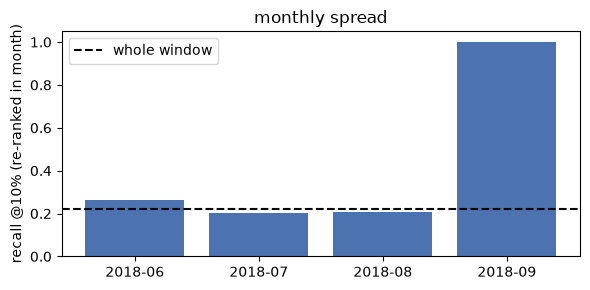

months not judged (< 500 labelled orders): ['2018-09']
second metric -- last judged evaluation month 2018-08: recall 0.2060, AUC 0.5730 on 6594 labelled orders; monthly range 0.0597


In [7]:
months = pd.DataFrame(ev["months"])
display(months)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(months["month"], months["recall"], color="#4c72b0")
ax.axhline(op["recall"], color="black", ls="--", label="whole window")
ax.set_ylabel("recall @10% (re-ranked in month)"); ax.legend(); ax.set_title("monthly spread")
plt.tight_layout(); plt.show()
judged = M["drift_vs_model"]
last = judged["last_full_month"]
print(f"months not judged (< {judged['min_month_labelled']} labelled orders): {judged['months_not_judged']}")
print(f"second metric -- last judged evaluation month {last['month']}: recall {last['recall']:.4f}, "
      f"AUC {last['auc']:.4f} on {last['labelled']} labelled orders; monthly range {judged['recall_range']:.4f}")

## ۵. جابه‌جایی داده (Drift): پنجرهٔ آموزش در برابر پنجرهٔ ارزیابی

,psi,kind,feature,ks_pvalue,eval_median,eval_missing,ks_statistic,train_median,train_missing,eval_top,train_top
0,0.8505,number,shipping_limit_days,0.0000,4.0000,0.0017,0.3331,6.0000,0.0074,NaN,NaN
1,0.3918,number,promise_days,0.0000,19.9843,0.0000,0.2465,23.5418,0.0000,NaN,NaN
2,0.2751,number,freight_sum,0.0000,18.5900,0.0000,0.1712,16.7900,0.0000,NaN,NaN
3,0.1759,category,product_category_name_english,NaN,NaN,NaN,NaN,NaN,NaN,health_beauty 0.120,bed_bath_table 0.095
4,0.0353,category,seller_state,NaN,NaN,NaN,NaN,NaN,NaN,SP 0.696,SP 0.706
5,0.0316,number,product_weight_g,0.0000,600.0000,0.0017,0.0580,700.0000,0.0076,NaN,NaN
6,0.0259,number,product_photos_qty,0.0508,1.0000,0.0065,0.0110,2.0000,0.0239,NaN,NaN
7,0.0239,number,approval_hour,0.0000,14.0000,0.0000,0.0426,13.0000,0.0000,NaN,NaN
8,0.0234,number,customer_seller_span_sq,0.0000,14.2128,0.0059,0.0549,17.3120,0.0125,NaN,NaN
9,0.0201,number,approval_day_of_month,0.0000,15.0000,0.0000,0.0490,16.0000,0.0000,NaN,NaN


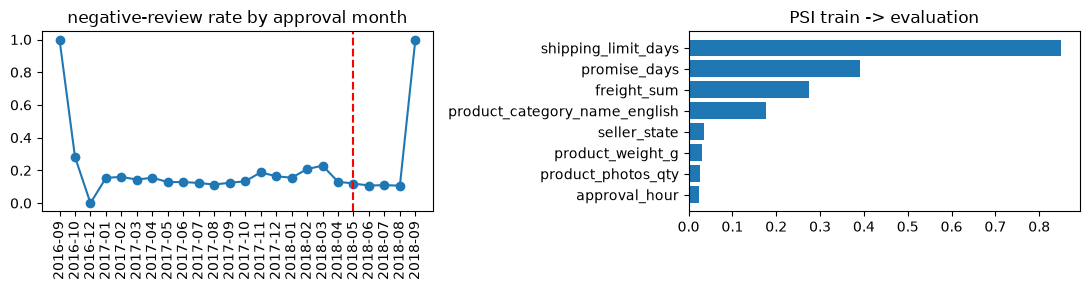

In [8]:
drift = pd.DataFrame(M["drift"])
display(drift.head(12).round(4))
nr = pd.DataFrame(M["negative_rate_by_month"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(nr["month"], nr["negative_rate"], marker="o")
axes[0].axvline(str(CONFIG.split.boundary)[:7], color="red", ls="--")
axes[0].set_title("negative-review rate by approval month"); axes[0].tick_params(axis="x", rotation=90)
top = drift.head(8)
axes[1].barh(top["feature"], top["psi"]); axes[1].invert_yaxis(); axes[1].set_title("PSI train -> evaluation")
plt.tight_layout(); plt.show()

## ۶. منبع بیرونی (IBGE، چگالی جمعیت ۲۰۱۰): با و بدون

,0
model,hgb.d3
column,external_density_2010
coverage,0.992607
available,True
eval_auc_with,0.606333
eval_auc_without,0.603012
eval_recall_with,0.227786
eval_recall_without,0.222877
validation_recall_with,0.195852
validation_recall_without,0.198222


eval recall@10% delta (with - without), 95% bootstrap: {'low': -0.0019831153476686713, 'high': 0.011930849528208698, 'mean': 0.00486120765644655, 'rounds': 200}


,orders,quartile,negative_rate,density_median
0,19841,q1 (sparse),0.139912,47.00
1,19764,q2,0.149868,398.32
2,21886,q3,0.184958,3639.94
3,17561,q4 (dense),0.144923,7387.69


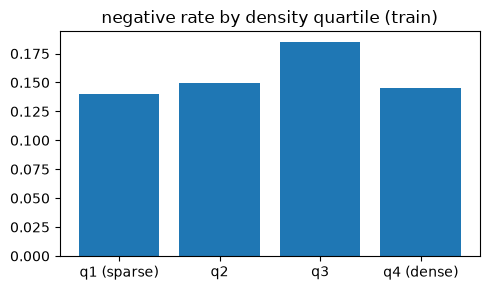

In [9]:
ext = M["external"]
display(pd.DataFrame([{k: v for k, v in ext.items() if k not in ("negative_rate_by_density_quartile", "eval_recall_delta_ci95")}]).T)
print("eval recall@10% delta (with - without), 95% bootstrap:", ext.get("eval_recall_delta_ci95"))
q = pd.DataFrame(ext.get("negative_rate_by_density_quartile", []))
if not q.empty:
    display(q)
    fig, ax = plt.subplots(figsize=(5, 3)); ax.bar(q["quartile"], q["negative_rate"]); ax.set_title("negative rate by density quartile (train)")
    plt.tight_layout(); plt.show()

## ۷. هزینهٔ نشت: مدل تقلبی با ستون‌های وسوسه‌کننده

In [10]:
print((STAGE / "docs/evidence/cheating-model-gap.txt").read_text())

# cheating-model gap (scripts/cheating_model_gap.py)
model family: hgb.d3; split boundary 2018-05-31 (config capstone.default.toml, seed 20181); evaluation window ['2018-06', '2018-07', '2018-08', '2018-09']; quota 10%
tempting columns added: order_status, order_delivered_customer_date (as delivery_days and late_days), order_delivered_carrier_date (as carrier_days)

| model | recall@5% | recall@10% | recall@20% | precision@10% | AUC |
|---|---:|---:|---:|---:|---:|
| real model | 0.1487 | 0.2229 | 0.3348 | 0.2406 | 0.6030 |
| cheating model, leaked values | 0.2926 | 0.4094 | 0.5209 | 0.4420 | 0.7255 |
| cheating model, values as at approval | 0.0967 | 0.1610 | 0.2857 | 0.1738 | 0.5874 |

gap at the 10% quota, leaked notebook number minus real: +0.1865 (0.4094 vs 0.2229)
what the cheating model actually delivers at approval time: 0.1610 (-0.0619 vs the real model)



## ۸. خروجی عملیاتی و مسیر پیش‌بینی

In [11]:
followup = pd.read_csv(CURATED / "followup_list.csv")
print("follow-up list:", len(followup), "orders (top", CONFIG.capacity.share, "of the evaluation window)")
display(followup.head(10))
print((STAGE / "docs/evidence/sealed-cut-rehearsal.txt").read_text())

follow-up list: 1897 orders (top 0.1 of the evaluation window)


,rank,order_id,order_approved_at,score,model_run_id
0,1,2c990009034e1fc83904584b26b5fd25,2018-07-18 10:05:20,0.883223,run-20261127T165412Z
1,2,05c852fbe20c108caf9f479633cbe088,2018-07-13 15:10:16,0.877590,run-20261127T165412Z
2,3,84b8ba39037606b7b30a39d02e9e4154,2018-06-27 20:11:41,0.866882,run-20261127T165412Z
3,4,b635cbb9f7c2bc5de438f7429b8490e5,2018-08-05 23:30:50,0.865139,run-20261127T165412Z
4,5,93881917b8e0f2bf11eec7abbbfe43ec,2018-08-11 21:50:11,0.862191,run-20261127T165412Z
5,6,e55fa3385fa77f6be6a0041c5daf2fb6,2018-08-06 23:31:35,0.849614,run-20261127T165412Z
6,7,d6f1fd48e3b9fbaa5ed2794838559afb,2018-06-26 00:18:00,0.838611,run-20261127T165412Z
7,8,02de1e44936e56ddc1621c46d86bf91e,2018-08-21 12:35:12,0.836039,run-20261127T165412Z
8,9,4cccc0d35e7c7a0dc766ad3c4043e33e,2018-08-10 10:50:21,0.834640,run-20261127T165412Z
9,10,bcd65d5c97ac448bb3efc90b759909fd,2018-07-20 16:44:16,0.832225,run-20261127T165412Z


# sealed-cut rehearsal, month 2018-08 (scripts/sealed_cut_rehearsal.py)
bundle: data/raw/sealed_cut_2018-08/ (orders, customers, items, payments, products, sellers; no reviews)
orders in the cut: 6620; scored: 6620; follow-up list: 662; not scored (no order_approved_at): 0
model: hgb.d3 run run-20261127T165412Z
config capstone.default.toml; seed 20181

## 1. same preparation: predict vs the model step's stored score for the same order
orders compared: 6620 of 6620; max |difference|: 4.999903863989186e-07

## 2. same metric: recall of negative reviews at each capacity, labelled orders of the cut
labelled orders: 6594; negatives: 704
  5%: reviewed 330, caught 109, recall 0.1548
  10%: reviewed 660, caught 145, recall 0.2060
  20%: reviewed 1319, caught 206, recall 0.2926
model step, same month, 10%: recall 0.2060 (145 of 704)



## ۹. دو شاهدِ دیگرِ گزارش: زمانِ کوئریِ ویژگی (سقف ۵۰۰ ms، با پلن) و حساسیتِ مرز

هر دو را اسکریپت‌هایی جدا از زنجیره نوشته‌اند (`scripts/analyze_ceiling_feature.py --tag …` و
`scripts/boundary_sensitivity.py`)؛ این‌جا فقط خوانده می‌شوند تا هر عددِ `report.md` در نوتبوک هم دیده شود.
زمانِ قاب روی این دیتابیس هم یک بار دوباره گرفته می‌شود (`features.FRAME_TIMING_SQL`، بهترینِ پنج اجرا).

In [12]:
import time
from capstone import features
ceiling = sorted((STAGE / "docs/evidence").glob("ceiling-feature-analysis.sandbox-*.txt"))[-1]
print(ceiling.name)
print("\n".join(line for line in ceiling.read_text().splitlines()[:8] if line.strip()))
runs = []
for _ in range(5):
    start = time.perf_counter(); cur.execute(features.FRAME_TIMING_SQL.format(frame=features.FRAME_VIEW)); cur.fetchall()
    runs.append((time.perf_counter() - start) * 1000)
print(f"this database, now: best {min(runs):.1f} ms of 5 (ceiling {CONFIG.features.feature_query_ms} ms)")
print((STAGE / "docs/evidence/boundary-sensitivity.txt").read_text())
conn.close()

ceiling-feature-analysis.sandbox-2026-11-27.txt
# ceiling on the feature frame, measured across one ANALYZE (scripts/analyze_ceiling_feature.py)
config capstone.default.toml; frame capstone.v_feature_frame; ceiling 500 ms; frame rows 99281
basis: best of the repeats, the same statistic the feature step judges on
before ANALYZE: best 357.2 ms, mean 366.9 ms, worst 392.7 ms, runs [392.738, 370.55, 367.743, 359.198, 357.194, 362.626, 358.944, 358.997, 369.76, 361.882, 368.892, 364.901, 367.011, 371.626, 371.672]; 15/15 repeats under the ceiling, fastest was repeat 5 of 15 | read with transfer, one sample: 798.5 ms | spread 35.5 ms, drift -0.2 ms, the ceiling is outside it
after  ANALYZE: best 360.7 ms, mean 367.0 ms, worst 384.1 ms, runs [366.124, 365.378, 364.955, 366.415, 371.223, 368.571, 384.064, 366.278, 360.666, 360.731, 367.632, 364.899, 367.072, 361.705, 368.752]; 15/15 repeats under the ceiling, fastest was repeat 9 of 15 | read with transfer, one sample: 805.0 ms | spread 23.4 m

this database, now: best 354.6 ms of 5 (ceiling 500 ms)
# boundary sensitivity (scripts/boundary_sensitivity.py)
config capstone.default.toml; decided boundary 2018-05-31; seed 20181; quota 10%; frame rows 99281; roster logreg.c0_1, logreg.c1, hgb.d3, hgb.d6
only split.boundary changes between rows; selection is on the last 3 months before each boundary, evaluation on everything after it

| boundary | train rows (neg) | eval rows / labelled (neg) | eval months | chosen | recall@5% | recall@10% | recall@20% | AUC | rule@10% | last judged month |
|---|---|---|---|---|---:|---:|---:|---:|---:|---|
| 2018-05-31 | 80320 (12417) | 18961 / 18864 (2037) | 2018-06, 2018-07, 2018-08, 2018-09 | hgb.d3 | 0.1487 | 0.2229 | 0.3348 | 0.6030 | 0.2150 | 2018-08 0.2060 |
| 2018-06-30 | 86484 (13077) | 12797 / 12725 (1377) | 2018-07, 2018-08, 2018-09 | hgb.d3 | 0.1402 | 0.2164 | 0.3261 | 0.5994 | 0.1903 | 2018-08 0.2131 |
| 2018-07-31 | 92660 (13749) | 6621 / 6595 (705) | 2018-08, 2018-09 | hgb.d3 | 0.15